In [1]:
import sys, os
from pathlib import Path

PROJECT_ROOT = Path(os.getcwd()).resolve()
while not (PROJECT_ROOT / 'setup.py').exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError('Cannot find project root')
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
import sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from solve_dae.integrate import solve_dae
from solve_dae.integrate import solve_dae

ROOT = Path("../..").resolve()
sys.path.insert(0, str(ROOT / "scripts" / "utils"))
import json
from simulate_HFR import build_atol, soc_cutoff_event
from simulate_sensitivity import build_cell_op, build_cell_conf
from rfbmodel1D.parameters.params import membraneparams, cathodeparams, agdlparams, cellparams, anodeparams

In [2]:
# -- baseline operating point --------------------------------------------------
TEST_NO  = 1           # integer 1-29
MODE     = "discharge"   # "charge" or "discharge"
J_INDEX  = 8             # index into the current-density list for the chosen mode 

# -- load experimental data and pick the point ---------------------------------
csv  = ROOT / "data" / "experimental" / "HFR.csv"
data = pd.read_csv(csv)
data = data[data["test_no"] == TEST_NO]

soc = data["SOC"].iloc[0]
T   = data["T(°C)"].iloc[0]
Q_v = data["Q_v (ml/min)"].iloc[0]

mode_data = data[data["mode"] == MODE]
j_list    = mode_data["j_appl (A/m2)"].values
HFR_list  = mode_data["value (ohm cm2)"].values

j_appl_raw = float(j_list[J_INDEX])
j_appl     = j_appl_raw if MODE == "charge" else -j_appl_raw   # negative for discharge
HFR_exp    = float(HFR_list[J_INDEX])

# -- baseline configuration (geometry/structural) values, from params.py -------
CATHODE_POROSITY_BASE   = cathodeparams.porosity              # [-]
AGDL_POROSITY_BASE      = agdlparams.porosity                 # [-]
MEMBRANE_THICKNESS_BASE = membraneparams.thickness            # [m]
CATHODE_SSA_BASE        = cathodeparams.specific_surface_area # [m2/m3]
CATHODE_THICKNESS_BASE  = cathodeparams.thickness             # [m]

# -- sweep ranges (one-at-a-time around the baseline) ---------------------------
C_POROSITY_VALUES    = [0.92, 0.93, 0.94, 0.95]
AGDL_POROSITY_VALUES = [0.5, 0.6, 0.7, 0.8]
M_THICKNESS_VALUES   = [25e-6, 50e-6, 120e-6, 200e-6]      
C_SSA_VALUES         = [3e4, 6e4, 1.44e5, 4.29e5] 
C_THICKNESS_VALUES   = [3.5e-3, 4e-3, 4.6e-3, 5e-3]      


# -- solver settings --------------------------------------------------------------
TF   = 1800   # simulation duration [s]
RTOL = 1e-5

In [3]:
# -- sorption / desorption kinetics  ------ from HFR fitting
fit_dir  = ROOT / "results" / "test fitting" / f"test {TEST_NO}"
HFR_FIT    = sorted(fit_dir.glob(f"HFR_fit_test{TEST_NO}_*.json"))[-1].name
if HFR_FIT is not None:
    with open(fit_dir / HFR_FIT) as f:
        _hfr = json.load(f)
    _p = _hfr["params"]
    membraneparams.k_sorp_vw   = _p["k_vw_sorp"]
    membraneparams.k_desorp_vw = _p["S_desorp"] * _p["k_vw_sorp"]
    membraneparams.k_sorp_lw   = _p["k_lw_sorp"]
    membraneparams.k_desorp_lw = _p["S_desorp"] * _p["k_lw_sorp"]
    membraneparams.k_ca_lw     = _p["k_ca"]
    membraneparams.sf_D        = 1
    cellparams.vanadium_uptake = False
    print(f"Membrane params loaded from: {HFR_FIT}")
# -- from e_cell_fitting
fit_dir_cell  = ROOT / "results" / "test fitting" / "global" 
E_CELL_FIT    = sorted(fit_dir_cell.glob(f"global_k_ca_fit_{int(T)}.json"))[-1].name
if E_CELL_FIT is not None:
    with open(fit_dir_cell / E_CELL_FIT) as f:
        _cell = json.load(f)
    _p = _cell["params"]
    cathodeparams.reaction_rate_constant     = _p["k_ca"]
    anodeparams.j_0                          = _p["j0_an"][f"{TEST_NO}"]
    print(f"Membrane params loaded from: {E_CELL_FIT}")


Membrane params loaded from: HFR_fit_test1_20260820_144334.json
Membrane params loaded from: global_k_ca_fit_24.json


## Helper functions

In [4]:
def run_case_conf(soc, j_appl, T, Q_v, RH=1, TF=TF, RTOL=RTOL,
                   cathode_porosity=None, agdl_porosity=None,
                   membrane_thickness=None, cathode_ssa=None, cathode_thickness=None):
    """Build and solve one configuration, returning (cell, sol)."""
    cell, y0, yp0 = build_cell_conf(
        soc, j_appl, T, Q_v, RH,
        cathode_porosity=cathode_porosity, agdl_porosity=agdl_porosity,
        membrane_thickness=membrane_thickness, cathode_ssa=cathode_ssa,
        cathode_thickness=cathode_thickness,
    )
    atol         = build_atol(cell)
    jac_sparsity = cell.compute_jac_sparsity(y0, yp0)
    sol = solve_dae(
        cell.dae_residual_full_cell,
        (0.0, TF), y0, yp0,
        method="BDF", atol=atol, rtol=RTOL,
        events=soc_cutoff_event, jac_sparsity=jac_sparsity,
    )
    return cell, sol


def compute_HFR(cell):
    """Cell HFR [Ohm.cm2] from the last evaluated state (cathode + membrane + electronic)."""
    kappa_io_ca = cell.cathode.kappa_io
    sigma_ca    = np.ones_like(kappa_io_ca) * cell.cathode.eff_conductivity
    dx_ca       = cell.mesh.cathode_mesh.dx * cell.cathode.thickness
    R_cathode   = float(np.sum(dx_ca / (sigma_ca + kappa_io_ca)))

    kappa_io_m = cell.membrane.kappa_io
    dx_m       = cell.mesh.membrane_mesh.dx * cell.membrane.thickness
    R_membrane = float(np.sum(dx_m / kappa_io_m))

    R_ACL  = cell.anode.thickness  / cell.anode.eff_conductivity
    R_AGDL = cell.agdl.thickness   / cell.agdl.eff_conductivity
    R_BP   = cell.thickness_BP / cell.sigma_BP
    R_CC   = cell.thickness_CC / cell.sigma_CC

    return (R_cathode + R_membrane + R_ACL + R_AGDL + R_BP + R_CC) * 1e4


def compute_E_cell(cell, sol):
    """Cell voltage [V] from the last evaluated state."""
    ysol = sol.y

    Nc     = cell.mesh.cathode_mesh.n_x
    n_tank = cell.layout.n_vars_tank
    n_ca   = cell.layout.n_vars_cathode

    y_ca_all     = ysol[n_tank:n_tank + Nc * n_ca, :].reshape(Nc, n_ca, -1)
    Phi_el_final = y_ca_all[:, 4, -1]  # First node, 4th variable, last time
    dx           = cell.mesh.cathode_mesh.dx[0] * cell.cathode.thickness
    sigma_el     = cell.cathode.eff_conductivity
    return float(Phi_el_final[0] + j_appl * (dx / 2) / sigma_el)


def extract_diagnostics(cell, sol):
    """Time series of membrane hydration and tank SOC, plus scalar in-plane velocity."""
    tsol = sol.t
    ysol = sol.y

    Nc     = cell.mesh.cathode_mesh.n_x
    Nm     = cell.mesh.membrane_mesh.n_x
    n_tank = cell.layout.n_vars_tank
    n_ca   = cell.layout.n_vars_cathode
    n_mem  = cell.layout.n_vars_membrane

    off_ca  = n_tank
    off_mem = off_ca + Nc * n_ca

    y_mem_all  = ysol[off_mem:off_mem + Nm * n_mem, :].reshape(Nm, n_mem, -1)
    lambda_mem = y_mem_all[:, 0, :]

    c_V4, c_V5 = ysol[0, :], ysol[1, :]
    den      = c_V4 + c_V5
    SOC_time = np.divide(c_V5, den, out=np.zeros_like(c_V5), where=den > 0)

    return {
        "t": tsol,
        "lambda_mem_mean": lambda_mem.mean(axis=0),
        "lambda_mem_min":  lambda_mem.min(axis=0),
        "SOC": SOC_time,
        "u_ip": cell.cathode.u_ip,
    }


# -- baseline configuration kwargs, held fixed except for the swept parameter ---
base_kwargs_conf = dict(
    soc=soc, j_appl=j_appl, T=T, Q_v=Q_v, RH=1,
    cathode_porosity=CATHODE_POROSITY_BASE,
    agdl_porosity=AGDL_POROSITY_BASE,
    membrane_thickness=MEMBRANE_THICKNESS_BASE,
    cathode_ssa=CATHODE_SSA_BASE,
    cathode_thickness=CATHODE_THICKNESS_BASE,
)


def run_sweep_conf(param_name, values, **base_kwargs):
    """Run run_case_conf() varying *param_name* over *values*, holding others at base_kwargs."""
    results = {}
    for val in values:
        kwargs = dict(base_kwargs)
        kwargs[param_name] = val
        print(f"Running {param_name}={val} ...")
        try:
            cell, sol = run_case_conf(**kwargs)
        except Exception as exc:
            print(f"  FAILED: {exc!r}")
            results[val] = {"success": False, "error": str(exc)}
            continue
        diag = extract_diagnostics(cell, sol)
        diag["HFR"]     = compute_HFR(cell)
        diag["E_cell"]  = compute_E_cell(cell, sol)
        diag["success"] = sol.success
        diag["t_end"]   = sol.t[-1]
        results[val] = diag
        print(f"  success={sol.success}  t_end={sol.t[-1]:.1f}/{TF}  "
              f"HFR={diag['HFR']:.3f} Ohm.cm2  E_cell={diag['E_cell']:.4f} V  "
              f"u_ip={diag['u_ip']*1e3:.4f} mm/s  "
              f"lambda_mean(end)={diag['lambda_mem_mean'][-1]:.2f}")
    return results


def plot_sweep_conf(results, values, xlabel, title_prefix, cmap=plt.cm.viridis):
    """Plot membrane-hydration time series, HFR, and E_cell vs. the swept value."""
    ok_values = [v for v in values if results[v].get("success", False)]

    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    colors = cmap(np.linspace(0.1, 0.9, len(ok_values)))

    for c, val in zip(colors, ok_values):
        d = results[val]
        axes[0].plot(d["t"], d["lambda_mem_mean"], color=c, lw=2, label=f"{val:g}")

    axes[0].set_title(r"Membrane $\lambda$ (mean)")
    axes[0].set_xlabel("Time [s]")
    axes[0].set_ylabel(r"$\lambda$ [-]")
    axes[0].legend(fontsize=8, title=xlabel)
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(ok_values, [results[v]["HFR"] for v in ok_values], "o-", lw=2)
    axes[1].set_xlabel(xlabel)
    axes[1].set_ylabel(r"HFR [$\Omega\cdot$cm$^2$]")
    axes[1].set_title(r"HFR at $t_{end}$")
    axes[1].grid(True, alpha=0.3)

    axes[2].plot(ok_values, [results[v]["E_cell"] for v in ok_values], "o-", lw=2, color="tab:red")
    axes[2].ticklabel_format(useOffset=False)
    axes[2].set_xlabel(xlabel)
    axes[2].set_ylabel(r"$E_{cell}$ [V]")
    axes[2].set_title(r"$E_{cell}$ at $t_{end}$")
    axes[2].grid(True, alpha=0.3)

    fig.suptitle(f"{title_prefix}  |  SOC={soc:.2f}, j={j_appl:+.0f} A/m2, T={T:.0f} degC, Q_v={Q_v:.0f} ml/min",
                  fontsize=12, fontweight="bold")
    fig.tight_layout()
    plt.show()

## Cathode porosity sweep

Note: porosity must lie in (0, 1) for the model to be physically meaningful;
values >= 1 in `C_POROSITY_VALUES` are kept for now as placeholders and will
likely fail (caught by `run_sweep_conf` and skipped in the plots).

In [5]:
results_C_POROSITY = run_sweep_conf("cathode_porosity", C_POROSITY_VALUES, **base_kwargs_conf)

Running cathode_porosity=0.92 ...
  success=True  t_end=1800.0/1800  HFR=0.722 Ohm.cm2  E_cell=0.9152 V  u_ip=1.0944 mm/s  lambda_mean(end)=7.84
Running cathode_porosity=0.93 ...
  success=True  t_end=1800.0/1800  HFR=0.730 Ohm.cm2  E_cell=0.9257 V  u_ip=1.1603 mm/s  lambda_mean(end)=7.84
Running cathode_porosity=0.94 ...
  success=True  t_end=1800.0/1800  HFR=0.738 Ohm.cm2  E_cell=0.9298 V  u_ip=1.2244 mm/s  lambda_mean(end)=7.84
Running cathode_porosity=0.95 ...
  success=True  t_end=1800.0/1800  HFR=0.745 Ohm.cm2  E_cell=0.9294 V  u_ip=1.2849 mm/s  lambda_mean(end)=7.84


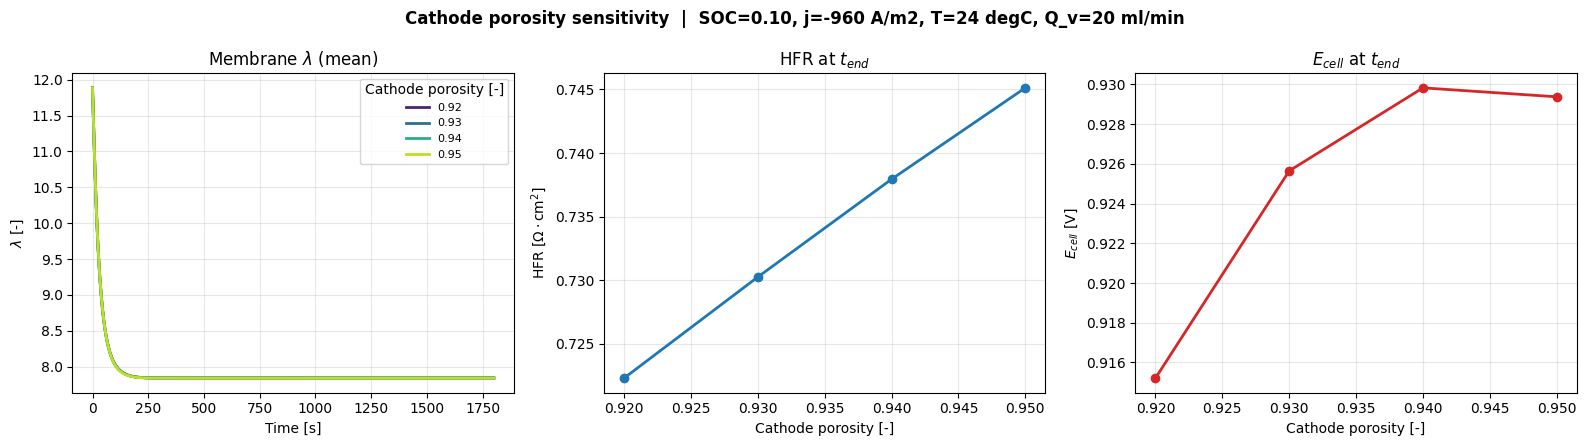

In [6]:
plot_sweep_conf(results_C_POROSITY, C_POROSITY_VALUES, "Cathode porosity [-]",
                "Cathode porosity sensitivity", cmap=plt.cm.viridis)

## AGDL porosity sweep

In [7]:
results_AGDL_POROSITY = run_sweep_conf("agdl_porosity", AGDL_POROSITY_VALUES, **base_kwargs_conf)

Running agdl_porosity=0.5 ...
  success=True  t_end=1800.0/1800  HFR=0.738 Ohm.cm2  E_cell=0.9297 V  u_ip=1.2244 mm/s  lambda_mean(end)=7.84
Running agdl_porosity=0.6 ...
  success=True  t_end=1800.0/1800  HFR=0.738 Ohm.cm2  E_cell=0.9298 V  u_ip=1.2244 mm/s  lambda_mean(end)=7.84
Running agdl_porosity=0.7 ...
  success=True  t_end=1800.0/1800  HFR=0.738 Ohm.cm2  E_cell=0.9299 V  u_ip=1.2244 mm/s  lambda_mean(end)=7.84
Running agdl_porosity=0.8 ...
  success=True  t_end=1800.0/1800  HFR=0.739 Ohm.cm2  E_cell=0.9299 V  u_ip=1.2244 mm/s  lambda_mean(end)=7.85


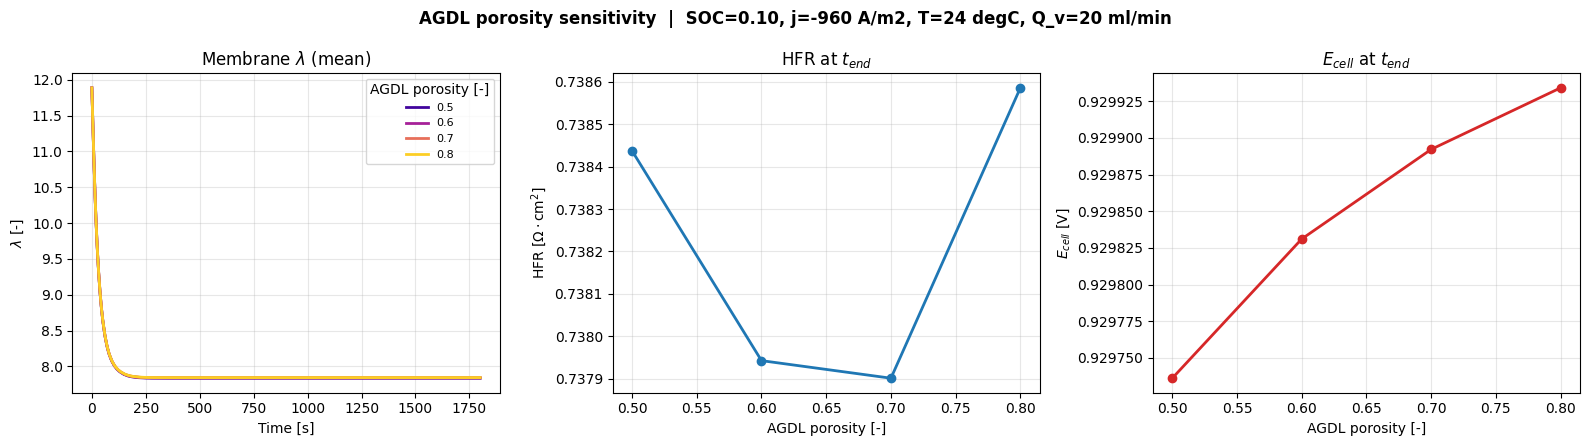

In [8]:
plot_sweep_conf(results_AGDL_POROSITY, AGDL_POROSITY_VALUES, "AGDL porosity [-]",
                "AGDL porosity sensitivity", cmap=plt.cm.plasma)

## Membrane thickness sweep

In [9]:
results_M_THICKNESS = run_sweep_conf("membrane_thickness", M_THICKNESS_VALUES, **base_kwargs_conf)

Running membrane_thickness=2.5e-05 ...
  success=True  t_end=1800.0/1800  HFR=0.262 Ohm.cm2  E_cell=0.9802 V  u_ip=1.2244 mm/s  lambda_mean(end)=9.45
Running membrane_thickness=5e-05 ...
  success=True  t_end=1800.0/1800  HFR=0.350 Ohm.cm2  E_cell=0.9710 V  u_ip=1.2244 mm/s  lambda_mean(end)=9.03
Running membrane_thickness=0.00012 ...
  success=True  t_end=1800.0/1800  HFR=0.691 Ohm.cm2  E_cell=0.9349 V  u_ip=1.2244 mm/s  lambda_mean(end)=7.95
Running membrane_thickness=0.0002 ...
Call 20000: t=1188.320772, max|res|=1.335817e-03
  success=True  t_end=1800.0/1800  HFR=2.521 Ohm.cm2  E_cell=0.7239 V  u_ip=1.2244 mm/s  lambda_mean(end)=6.38


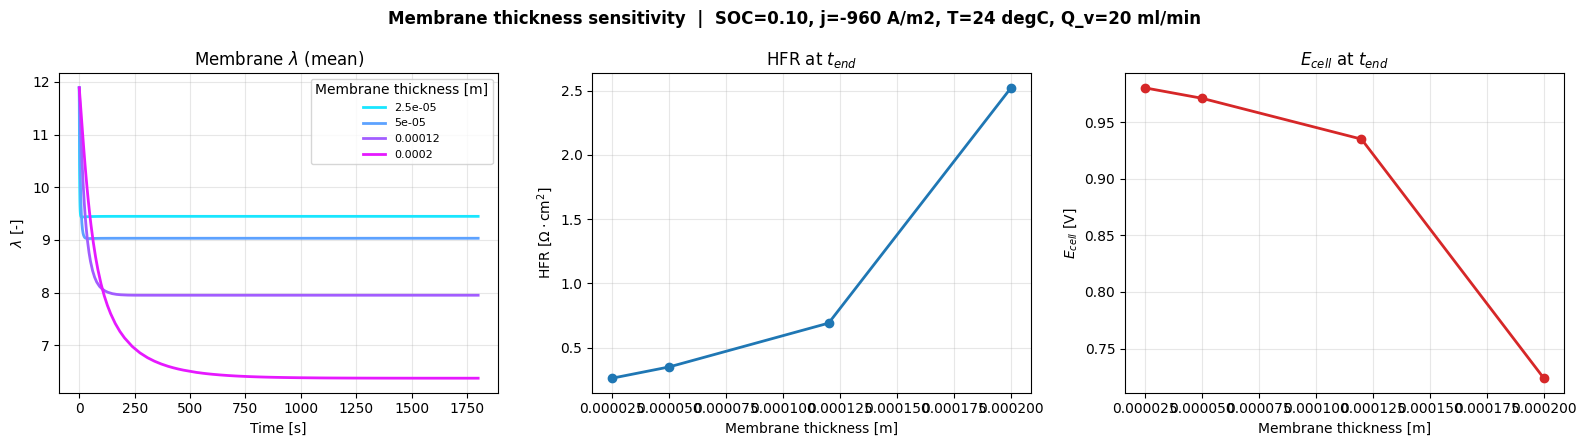

In [10]:
plot_sweep_conf(results_M_THICKNESS, M_THICKNESS_VALUES, "Membrane thickness [m]",
                "Membrane thickness sensitivity", cmap=plt.cm.cool)

## Cathode specific surface area sweep

In [11]:
results_C_SSA = run_sweep_conf("cathode_ssa", C_SSA_VALUES, **base_kwargs_conf)

Running cathode_ssa=30000.0 ...
  success=True  t_end=1800.0/1800  HFR=0.738 Ohm.cm2  E_cell=0.9298 V  u_ip=1.2244 mm/s  lambda_mean(end)=7.84
Running cathode_ssa=60000.0 ...
  success=True  t_end=1800.0/1800  HFR=0.738 Ohm.cm2  E_cell=0.9388 V  u_ip=1.2244 mm/s  lambda_mean(end)=7.84
Running cathode_ssa=144000.0 ...
  success=True  t_end=1800.0/1800  HFR=0.738 Ohm.cm2  E_cell=0.9472 V  u_ip=1.2244 mm/s  lambda_mean(end)=7.84
Running cathode_ssa=429000.0 ...
  success=True  t_end=1800.0/1800  HFR=0.738 Ohm.cm2  E_cell=0.9555 V  u_ip=1.2244 mm/s  lambda_mean(end)=7.84


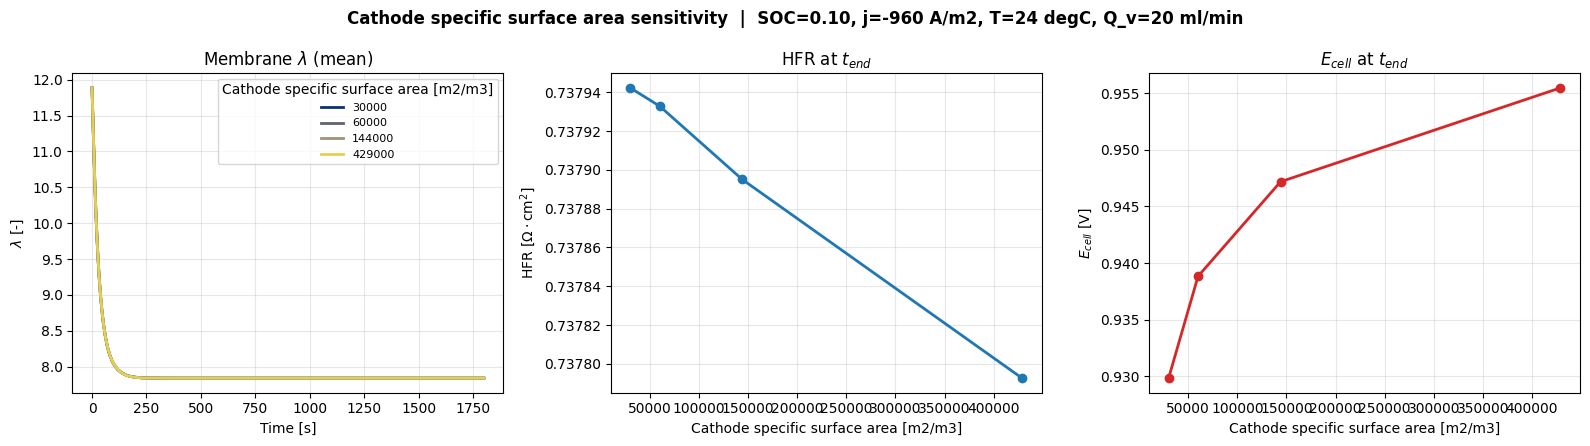

In [12]:
plot_sweep_conf(results_C_SSA, C_SSA_VALUES, "Cathode specific surface area [m2/m3]",
                "Cathode specific surface area sensitivity", cmap=plt.cm.cividis)

## Cathode thickness sweep

In [13]:
results_C_THICKNESS = run_sweep_conf("cathode_thickness", C_THICKNESS_VALUES, **base_kwargs_conf)

Running cathode_thickness=0.0035 ...
  success=True  t_end=1800.0/1800  HFR=0.694 Ohm.cm2  E_cell=0.9291 V  u_ip=1.5380 mm/s  lambda_mean(end)=7.84
Running cathode_thickness=0.004 ...
  success=True  t_end=1800.0/1800  HFR=0.714 Ohm.cm2  E_cell=0.9301 V  u_ip=1.3775 mm/s  lambda_mean(end)=7.84
Running cathode_thickness=0.0046 ...
  success=True  t_end=1800.0/1800  HFR=0.738 Ohm.cm2  E_cell=0.9298 V  u_ip=1.2244 mm/s  lambda_mean(end)=7.84
Running cathode_thickness=0.005 ...
  success=True  t_end=1800.0/1800  HFR=0.754 Ohm.cm2  E_cell=0.9291 V  u_ip=1.1401 mm/s  lambda_mean(end)=7.84


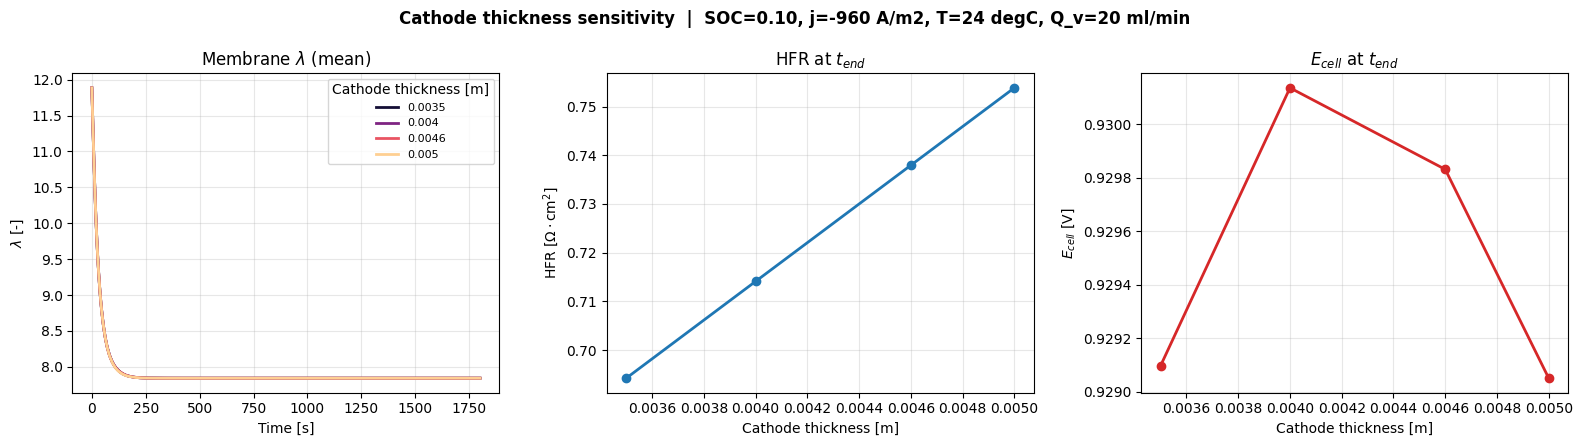

In [14]:
plot_sweep_conf(results_C_THICKNESS, C_THICKNESS_VALUES, "Cathode thickness [m]",
                "Cathode thickness sensitivity", cmap=plt.cm.magma)

## Configuration sensitivity tornado chart

One-at-a-time ±20 % perturbation of six structural parameters around the baseline
configuration loaded from `params.py`.  Both charge and discharge are simulated at
the same absolute current density, producing:

* **Voltage efficiency** = E\_cell,discharge / E\_cell,charge  
* **Discharge power density** = j × E\_cell,discharge  [W m⁻²]

Parameters swept: cathode thickness, membrane thickness, AGDL thickness,
AGDL porosity, cathode SSA, cathode porosity.  
Both charts share the same parameter order (sorted by VE impact range).

In [15]:
# -- User inputs ---------------------------------------------------------------
J_SENS_CONF  = abs(j_appl)   # absolute current density [A/m²] — defaults to test-case value
DELTA_CONF   = 0.20           # fractional perturbation (0.20 = ±20 %)
TF_CONF      = 300            # simulation duration per run [s]

In [16]:
AGDL_THICKNESS_BASE       = agdlparams.thickness       # [m]
CATHODE_CONDUCTIVITY_BASE = cathodeparams.conductivity  # [S/m]

def _E_cell_conf(cell, sol, j):
    Nc     = cell.mesh.cathode_mesh.n_x
    n_tank = cell.layout.n_vars_tank
    n_ca   = cell.layout.n_vars_cathode
    y_ca   = sol.y[n_tank:n_tank + Nc * n_ca, :].reshape(Nc, n_ca, -1)
    dx0    = cell.mesh.cathode_mesh.dx[0] * cell.cathode.thickness
    return float(y_ca[:, 4, -1][0] + j * (dx0 / 2) / cell.cathode.eff_conductivity)


def run_point_conf(cathode_thickness, membrane_thickness, agdl_thickness,
                   agdl_porosity, cathode_ssa, cathode_conductivity):
    """Run charge + discharge for one structural configuration, return VE and P."""
    E = {}
    for j in [+J_SENS_CONF, -J_SENS_CONF]:
        cell, y0, yp0 = build_cell_conf(
            soc=soc, j_appl=j, T=T, Q_v=Q_v, RH=1,
            cathode_thickness=cathode_thickness,
            membrane_thickness=membrane_thickness,
            agdl_thickness=agdl_thickness,
            agdl_porosity=agdl_porosity,
            cathode_ssa=cathode_ssa,
            cathode_conductivity=cathode_conductivity,
        )
        atol = build_atol(cell)
        sol  = solve_dae(
            cell.dae_residual_full_cell,
            (0.0, TF_CONF), y0, yp0,
            method="BDF", atol=atol, rtol=RTOL,
            events=soc_cutoff_event,
            jac_sparsity=cell.compute_jac_sparsity(y0, yp0),
        )
        E["charge" if j > 0 else "discharge"] = _E_cell_conf(cell, sol, j)
    VE = E["discharge"] / E["charge"]
    P  = J_SENS_CONF * E["discharge"]
    return {**E, "VE": VE, "P": P}


_base_conf = dict(
    cathode_thickness=CATHODE_THICKNESS_BASE,
    membrane_thickness=MEMBRANE_THICKNESS_BASE,
    agdl_thickness=AGDL_THICKNESS_BASE,
    agdl_porosity=AGDL_POROSITY_BASE,
    cathode_ssa=CATHODE_SSA_BASE,
    cathode_conductivity=CATHODE_CONDUCTIVITY_BASE,
)

param_defs_conf = {
    "cathode_thickness": {
        "label": f"Cathode thickness  ({CATHODE_THICKNESS_BASE*1e3:.1f} mm)",
        "base": CATHODE_THICKNESS_BASE,
        "clip": None,
    },
    "membrane_thickness": {
        "label": f"Membrane thickness  ({MEMBRANE_THICKNESS_BASE*1e6:.0f} μm)",
        "base": MEMBRANE_THICKNESS_BASE,
        "clip": None,
    },
    "agdl_thickness": {
        "label": f"AGDL thickness  ({AGDL_THICKNESS_BASE*1e6:.0f} μm)",
        "base": AGDL_THICKNESS_BASE,
        "clip": None,
    },
    "agdl_porosity": {
        "label": f"AGDL porosity  ({AGDL_POROSITY_BASE:.2f})",
        "base": AGDL_POROSITY_BASE,
        "clip": (0.01, 0.99),
    },
    "cathode_ssa": {
        "label": f"Cathode SSA  ({CATHODE_SSA_BASE:.2e} m² m⁻³)",
        "base": CATHODE_SSA_BASE,
        "clip": None,
    },
    "cathode_conductivity": {
        "label": f"Cathode conductivity  ({CATHODE_CONDUCTIVITY_BASE:.0f} S/m)",
        "base": CATHODE_CONDUCTIVITY_BASE,
        "clip": (1, None),
    },
}

print(f"Baseline — Test {TEST_NO}: SOC={soc:.2f}, T={T:.0f}°C, Q_v={Q_v:.0f} ml/min, "
      f"j = ±{J_SENS_CONF:.0f} A/m²")
for k, v in _base_conf.items():
    print(f"  {k} = {v:.4g}")

print("\nRunning baseline ...")
_base_res_conf = run_point_conf(**_base_conf)
print(f"  E_ch={_base_res_conf['charge']:.4f} V   E_di={_base_res_conf['discharge']:.4f} V   "
      f"VE={_base_res_conf['VE']:.4f}   P={_base_res_conf['P']:.2f} W/m²")

_sens_data_conf = {}
for pkey, pcfg in param_defs_conf.items():
    lo_val = pcfg["base"] * (1 - DELTA_CONF)
    hi_val = pcfg["base"] * (1 + DELTA_CONF)
    if pcfg["clip"]:
        lo_clip = pcfg["clip"][0]
        hi_clip = pcfg["clip"][1]
        if lo_clip is not None:
            lo_val = max(lo_val, lo_clip)
        if hi_clip is not None:
            hi_val = min(hi_val, hi_clip)
    _sens_data_conf[pkey] = {}
    for tag, val in [("lo", lo_val), ("hi", hi_val)]:
        pct = (val / pcfg["base"] - 1) * 100
        print(f"\n  {pkey} {tag} = {val:.4g}  ({pct:+.0f}%) ...")
        res = run_point_conf(**{**_base_conf, pkey: val})
        _sens_data_conf[pkey][tag] = res
        print(f"    E_ch={res['charge']:.4f} V   E_di={res['discharge']:.4f} V   "
              f"VE={res['VE']:.4f}   P={res['P']:.2f} W/m²")

print("\nDone.")

Baseline — Test 1: SOC=0.10, T=24°C, Q_v=20 ml/min, j = ±960 A/m²
  cathode_thickness = 0.0046
  membrane_thickness = 0.000127
  agdl_thickness = 0.000171
  agdl_porosity = 0.6
  cathode_ssa = 3e+04
  cathode_conductivity = 4400

Running baseline ...
  E_ch=1.1578 V   E_di=0.9299 V   VE=0.8031   P=892.23 W/m²

  cathode_thickness lo = 0.00368  (-20%) ...
    E_ch=1.1538 V   E_di=0.9297 V   VE=0.8057   P=892.05 W/m²

  cathode_thickness hi = 0.00552  (+20%) ...


<repo>\rfbmodel1D\cells\DAE\dae_residual_full_cell.py:565: RuntimeWarning: invalid value encountered in power
  D_vw_acl  = self.anode.D_vw * (T/333.15)**1.5 * (101325/(p_total_acl)) * (porosity_acl * (1 - s_acl))**1.5


    E_ch=1.1620 V   E_di=0.9277 V   VE=0.7983   P=890.13 W/m²

  membrane_thickness lo = 0.0001016  (-20%) ...
    E_ch=1.1523 V   E_di=0.9465 V   VE=0.8215   P=908.23 W/m²

  membrane_thickness hi = 0.0001524  (+20%) ...
    E_ch=1.1629 V   E_di=0.9068 V   VE=0.7798   P=870.13 W/m²

  agdl_thickness lo = 0.0001368  (-20%) ...
    E_ch=1.1579 V   E_di=0.9299 V   VE=0.8031   P=892.29 W/m²

  agdl_thickness hi = 0.0002052  (+20%) ...
    E_ch=1.1567 V   E_di=0.9298 V   VE=0.8038   P=892.17 W/m²

  agdl_porosity lo = 0.48  (-20%) ...
    E_ch=1.1578 V   E_di=0.9297 V   VE=0.8030   P=892.11 W/m²

  agdl_porosity hi = 0.72  (+20%) ...
    E_ch=1.1576 V   E_di=0.9299 V   VE=0.8033   P=892.29 W/m²

  cathode_ssa lo = 2.4e+04  (-20%) ...
    E_ch=1.1586 V   E_di=0.9259 V   VE=0.7992   P=888.47 W/m²

  cathode_ssa hi = 3.6e+04  (+20%) ...
    E_ch=1.1572 V   E_di=0.9326 V   VE=0.8059   P=894.85 W/m²

  cathode_conductivity lo = 3520  (-20%) ...
    E_ch=1.1610 V   E_di=0.9251 V   VE=0.7968   P=

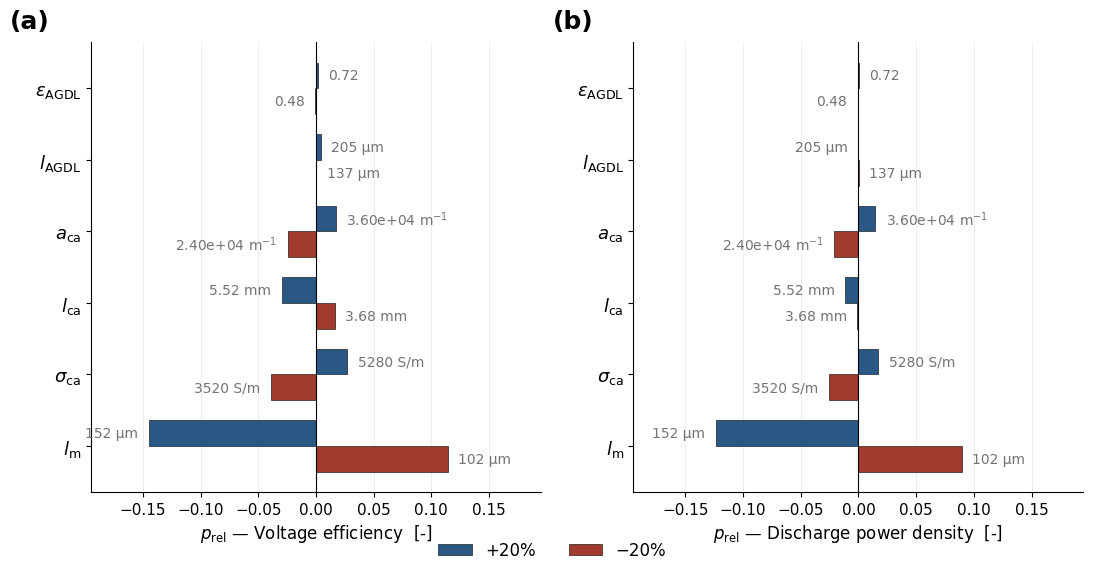

In [17]:
from matplotlib.patches import Patch

LABELS_SYM = {
    "cathode_thickness":    r"$l_\mathrm{ca}$",
    "membrane_thickness":   r"$l_\mathrm{m}$",
    "agdl_thickness":       r"$l_\mathrm{AGDL}$",
    "agdl_porosity":        r"$\varepsilon_\mathrm{AGDL}$",
    "cathode_ssa":          r"$a_\mathrm{ca}$",
    "cathode_conductivity": r"$\sigma_\mathrm{ca}$",
}

def _fmt(pkey, val):
    if pkey == "cathode_thickness":
        return f"{val*1e3:.2f} mm"
    if pkey in ("membrane_thickness", "agdl_thickness"):
        return f"{val*1e6:.0f} µm"
    if pkey == "agdl_porosity":
        return f"{val:.2f}"
    if pkey == "cathode_ssa":
        return f"{val:.2e} m$^{{-1}}$"
    if pkey == "cathode_conductivity":
        return f"{val:.0f} S/m"
    return f"{val:.3g}"


params_c  = list(param_defs_conf.keys())
labels_c  = [LABELS_SYM.get(p, p) for p in params_c]
base_VE_c = _base_res_conf["VE"]
base_P_c  = _base_res_conf["P"]

pert_vals_c = np.array([
    (pcfg["base"] * (1 - DELTA_CONF), pcfg["base"] * (1 + DELTA_CONF))
    for pcfg in [param_defs_conf[p] for p in params_c]
])

# p_rel = ΔY / (Y_base × DELTA_CONF)
pVE_c = np.array([
    [(_sens_data_conf[p]["lo"]["VE"] - base_VE_c) / (base_VE_c * DELTA_CONF),
     (_sens_data_conf[p]["hi"]["VE"] - base_VE_c) / (base_VE_c * DELTA_CONF)]
    for p in params_c
])
pP_c = np.array([
    [(_sens_data_conf[p]["lo"]["P"] - base_P_c) / (base_P_c * DELTA_CONF),
     (_sens_data_conf[p]["hi"]["P"] - base_P_c) / (base_P_c * DELTA_CONF)]
    for p in params_c
])

sort_idx_c = np.argsort(np.abs(pVE_c[:, 1] - pVE_c[:, 0]))[::-1]
labels_cs  = [labels_c[i] for i in sort_idx_c]
params_cs  = [params_c[i] for i in sort_idx_c]
pVE_cs     = pVE_c[sort_idx_c]
pP_cs      = pP_c[sort_idx_c]
pert_cs    = pert_vals_c[sort_idx_c]

COL_HI    = "#2A5783"
COL_LO    = "#A03B2D"
COL_LABEL = "0.45"
H         = 0.36
X_LIM     = 0.15
y_pos     = np.arange(len(params_cs))

fig, axes = plt.subplots(1, 2, figsize=(11, 5.5))

panel_info = [
    (axes[0], pVE_cs, r"$p_\mathrm{rel}$ — Voltage efficiency  [-]"),
    (axes[1], pP_cs,  r"$p_\mathrm{rel}$ — Discharge power density  [-]"),
]

for ax, data_s, xlabel in panel_info:
    pad = 0.06 * X_LIM
    ax.set_xlim(-X_LIM - 5 * pad, X_LIM + 5 * pad)

    for i in range(len(params_cs)):
        d_lo, d_hi = data_s[i]
        v_lo, v_hi = pert_cs[i]

        ax.barh(i + H / 2, d_hi, height=H, color=COL_HI,
                edgecolor="black", linewidth=0.4, zorder=3, clip_on=False)
        ax.barh(i - H / 2, d_lo, height=H, color=COL_LO,
                edgecolor="black", linewidth=0.4, zorder=3, clip_on=False)

        ax.text(d_hi + (pad if d_hi >= 0 else -pad), i + H / 2,
                _fmt(params_cs[i], v_hi),
                ha="left" if d_hi >= 0 else "right", va="center",
                fontsize=10, color=COL_LABEL, zorder=4)
        ax.text(d_lo + (pad if d_lo >= 0 else -pad), i - H / 2,
                _fmt(params_cs[i], v_lo),
                ha="left" if d_lo >= 0 else "right", va="center",
                fontsize=10, color=COL_LABEL, zorder=4)

    ax.axvline(0, color="black", lw=0.8, zorder=5)
    ax.set_yticks(y_pos)
    ax.set_yticklabels(labels_cs, fontsize=13)
    ax.tick_params(axis="x", labelsize=11)
    ax.set_xlabel(xlabel, fontsize=12)
    ax.grid(True, axis="x", alpha=0.3, linewidth=0.5, zorder=0)
    for spine in ("top", "right"):
        ax.spines[spine].set_visible(False)
    ax.set_box_aspect(1)

handles = [
    Patch(facecolor=COL_HI, edgecolor="black", linewidth=0.4,
          label=f"+{DELTA_CONF*100:.0f}%"),
    Patch(facecolor=COL_LO, edgecolor="black", linewidth=0.4,
          label=f"−{DELTA_CONF*100:.0f}%"),
]
fig.legend(handles=handles, fontsize=12, loc="lower center",
           ncol=2, frameon=False, bbox_to_anchor=(0.5, -0.02))

axes[0].text(-0.18, 1.02, "(a)", transform=axes[0].transAxes,
             fontsize=18, fontweight="bold", va="bottom")
axes[1].text(-0.18, 1.02, "(b)", transform=axes[1].transAxes,
             fontsize=18, fontweight="bold", va="bottom")

fig.tight_layout(rect=[0, 0.04, 1, 1])
plt.savefig(ROOT / "figures" / "sensitivity_analysis_conf.pdf", bbox_inches="tight")
plt.show()

## Configuration sensitivity vs. discharge current density: 3 tests x 3 current densities (9 panels)

Same one-at-a-time structural-parameter perturbation as the tornado chart
above, now repeated at 3 x 3 = 9 discharge operating points instead of a
single one: tests 5 / 16 / 25 (SOC low / mid / high), each at three discharge
current densities — two shared points (-500, -1500 A/m²) plus that test's
own **experimental maximum discharge current** (from `E_cell.csv`, same
source as the 9-point comparison below) — but at ±5 % (`DELTA_CONF_J`), not
the ±20 % used above (`DELTA_CONF`, untouched), and restricted to
**cathode + membrane** parameters only (`PARAMS_CONF_J`: cathode thickness,
cathode SSA, cathode conductivity, membrane thickness — dropping AGDL
thickness/porosity).

* **Scope** — this model's distinguishing feature relative to the prior
  (lumped) model is that the cathode and membrane are spatially resolved in
  1D. Restricting the comparison to cathode + membrane parameters makes this
  section answer a more targeted question — how much does that 1D resolution
  matter, and how does it vary with current density — rather than mixing in
  AGDL/anode effects that aren't the point of this comparison.
* **Operating point** — the max-discharge leg now uses each test's own
  actual experimental maximum (2015 / 4040 / 4040 A/m² for tests 5 / 16 /
  25) instead of a fixed placeholder, matching the -500 and -1500 A/m² legs.

**Bug fix — per-test E-cell kinetics.** `load_test_condition` /
`apply_test_condition` previously only loaded each test's HFR-fit membrane
parameters; the E-cell kinetics (`cathodeparams.reaction_rate_constant`,
`anodeparams.j_0`) were left at whatever the single baseline cell above
(`TEST_NO = 25`) had set, so tests 5 and 16 were silently simulated with
test 25's kinetics (visible in the old output: test 16 at max discharge gave
E_di = 0.40 V, an artifact of this). Both functions now also load and apply
the global-fit E-cell kinetics (`k_ca` shared, `j0_an` per test, from
`global_k_ca_{T}.json`) and the fit's own `sf_D` (previously hardcoded to
0.5), per test — same fix and loading pattern as `operating_sensitivity.ipynb`.
This also corrects the 9-point comparison section below, which shares these
same two functions.

Only discharge is simulated (no charge / VE ratio), so only **discharge
power density** `P = |j| x E_cell` is plotted (its *relative* sensitivity is
numerically identical to E_cell's within a panel, since |j| is fixed there
and cancels out of the p_rel ratio — so E_cell isn't shown separately).

In [18]:
# -- three tests x three discharge current densities (9 conditions) -----------
J_CONDITIONS = [
    {"label": "Low",  "test_no": 5},
    {"label": "Mid",  "test_no": 16},
    {"label": "High", "test_no": 25},
]
J_LABELS = ["-500 A/m2", "-1500 A/m2", "max discharge"]

ecell_df = pd.read_csv(ROOT / "data" / "experimental" / "E_cell.csv")
for cond in J_CONDITIONS:
    d = ecell_df[(ecell_df["test_no"] == cond["test_no"]) & (ecell_df["mode"] == "discharge")]
    j_max = float(d["j_appl (A/m2)"].max())
    cond["j_list"] = [-500.0, -1500.0, -j_max]
    print(f"Test {cond['test_no']}: max discharge j_appl = {j_max:.1f} A/m2  ->  j_list = {cond['j_list']}")

TF_CONF_J    = TF_CONF   # same short solve horizon as the tornado chart above
DELTA_CONF_J = 0.05      # smaller than DELTA_CONF (0.20) -- see markdown above
X_LIM_J      = 0.55      # shared x-axis half-width across all nine panels

# cathode + membrane only -- this model's 1D-resolved parts (see markdown)
PARAMS_CONF_J = ["cathode_thickness", "membrane_thickness", "cathode_ssa", "cathode_conductivity"]


def load_test_condition(test_no):
    """SOC / T / Q_v, HFR-fit membrane params, and global-fit E-cell kinetics for one test."""
    d = pd.read_csv(csv)
    d = d[d["test_no"] == test_no]
    T_t = float(d["T(°C)"].iloc[0])

    fit_dir = ROOT / "results" / "test fitting" / f"test {test_no}"
    hfr_fit = sorted(fit_dir.glob(f"HFR_fit_test{test_no}_*.json"))[-1]
    with open(hfr_fit) as f:
        _hfr = json.load(f)
    _p, _s = _hfr["params"], _hfr["settings"]

    fit_dir_cell = ROOT / "results" / "test fitting" / "global"
    ec_fit = sorted(fit_dir_cell.glob(f"global_k_ca_fit_{int(T_t)}.json"))[-1]
    with open(ec_fit) as f:
        _ec = json.load(f)

    return dict(
        soc=float(d["SOC"].iloc[0]), T=T_t,
        Q_v=float(d["Q_v (ml/min)"].iloc[0]),
        hfr_fit_name=hfr_fit.name, ec_fit_name=ec_fit.name,
        k_sorp_vw=_p["k_vw_sorp"], k_desorp_vw=_p["S_desorp"] * _p["k_vw_sorp"],
        k_sorp_lw=_p["k_lw_sorp"], k_desorp_lw=_p["S_desorp"] * _p["k_lw_sorp"],
        k_ca_lw=_p["k_ca"], sf_D=_s["sf_D"],
        k_ca=_ec["params"]["k_ca"], j0_an=_ec["params"]["j0_an"][f"{test_no}"],
    )


def apply_test_condition(c):
    membraneparams.k_sorp_vw   = c["k_sorp_vw"]
    membraneparams.k_desorp_vw = c["k_desorp_vw"]
    membraneparams.k_sorp_lw   = c["k_sorp_lw"]
    membraneparams.k_desorp_lw = c["k_desorp_lw"]
    membraneparams.k_ca_lw     = c["k_ca_lw"]
    membraneparams.sf_D        = c["sf_D"]
    cellparams.vanadium_uptake = False
    cathodeparams.reaction_rate_constant = c["k_ca"]
    anodeparams.j_0                      = c["j0_an"]


def run_point_discharge_conf(j_appl, soc, T, Q_v, **struct_kwargs):
    """Discharge-only counterpart of run_point_conf(): E_cell and power density."""
    cell, y0, yp0 = build_cell_conf(soc=soc, j_appl=j_appl, T=T, Q_v=Q_v, RH=1, **struct_kwargs)
    atol = build_atol(cell)
    sol = solve_dae(
        cell.dae_residual_full_cell,
        (0.0, TF_CONF_J), y0, yp0,
        method="BDF", atol=atol, rtol=RTOL,
        events=soc_cutoff_event,
        jac_sparsity=cell.compute_jac_sparsity(y0, yp0),
    )
    E_di = _E_cell_conf(cell, sol, j_appl)
    return {"E_cell": E_di, "P": abs(j_appl) * E_di, "success": sol.success, "t_end": sol.t[-1]}

Test 5: max discharge j_appl = 2014.7 A/m2  ->  j_list = [-500.0, -1500.0, -2014.669927]
Test 16: max discharge j_appl = 4040.2 A/m2  ->  j_list = [-500.0, -1500.0, -4040.201005]
Test 25: max discharge j_appl = 4040.3 A/m2  ->  j_list = [-500.0, -1500.0, -4040.302267]


In [ ]:
_results_by_j = {}
for cond in J_CONDITIONS:
    tn, label = cond["test_no"], cond["label"]
    c = load_test_condition(tn)
    apply_test_condition(c)
    print(f"\n{'='*70}\n{label}  |  test {tn}\n{'='*70}")
    print(f"  SOC={c['soc']:.2f}  T={c['T']:.0f} degC  Q_v={c['Q_v']:.0f} ml/min  "
          f"HFR fit: {c['hfr_fit_name']}  E-cell fit: {c['ec_fit_name']}")

    for j, j_label in zip(cond["j_list"], J_LABELS):
        print(f"\n  -- {j_label}  (j={j:+.1f} A/m2) --")
        base_res = run_point_discharge_conf(j, c["soc"], c["T"], c["Q_v"], **_base_conf)
        print(f"    baseline: E_di={base_res['E_cell']:.4f} V   P={base_res['P']:.2f} W/m2")

        sens = {}
        for pkey in PARAMS_CONF_J:
            pcfg = param_defs_conf[pkey]
            lo_val = pcfg["base"] * (1 - DELTA_CONF_J)
            hi_val = pcfg["base"] * (1 + DELTA_CONF_J)
            if pcfg["clip"]:
                lo_clip, hi_clip = pcfg["clip"]
                if lo_clip is not None: lo_val = max(lo_val, lo_clip)
                if hi_clip is not None: hi_val = min(hi_val, hi_clip)
            sens[pkey] = {}
            for tag, val in [("lo", lo_val), ("hi", hi_val)]:
                struct_kwargs = {**_base_conf, pkey: val}
                res = run_point_discharge_conf(j, c["soc"], c["T"], c["Q_v"], **struct_kwargs)
                sens[pkey][tag] = res
                print(f"    {pkey:22s} {tag}={val:.4g}: E_di={res['E_cell']:.4f} V  P={res['P']:.2f} W/m2")

        _results_by_j[(label, j_label)] = {
            "test_no": tn, "j": j, "loaded": c, "base": base_res, "sens": sens,
        }

print("\nAll 9 conditions done.")


Low  |  test 5
  SOC=0.10  T=32 degC  Q_v=45 ml/min  HFR fit: HFR_fit_test5_20260815_061952.json  E-cell fit: global_k_ca_fit_32.json

  -- -500 A/m2  (j=-500.0 A/m2) --
    baseline: E_di=1.0275 V   P=513.77 W/m2
    cathode_thickness      lo=0.00437: E_di=1.0281 V  P=514.06 W/m2
    cathode_thickness      hi=0.00483: E_di=1.0270 V  P=513.48 W/m2
    membrane_thickness     lo=0.0001206: E_di=1.0284 V  P=514.18 W/m2
    membrane_thickness     hi=0.0001334: E_di=1.0267 V  P=513.37 W/m2
    cathode_ssa            lo=2.85e+04: E_di=1.0275 V  P=513.73 W/m2
    cathode_ssa            hi=3.15e+04: E_di=1.0276 V  P=513.82 W/m2
    cathode_conductivity   lo=4180: E_di=1.0271 V  P=513.56 W/m2
    cathode_conductivity   hi=4620: E_di=1.0279 V  P=513.97 W/m2

  -- -1500 A/m2  (j=-1500.0 A/m2) --
    baseline: E_di=0.9002 V   P=1350.32 W/m2
    cathode_thickness      lo=0.00437: E_di=0.9019 V  P=1352.87 W/m2
    cathode_thickness      hi=0.00483: E_di=0.8985 V  P=1347.70 W/m2
    membrane_thickne

In [ ]:
params_j = list(PARAMS_CONF_J)
labels_j = [LABELS_SYM.get(p, p) for p in params_j]


def _p_rel(entry, metric):
    base = entry["base"][metric]
    return np.array([
        [(entry["sens"][p]["lo"][metric] - base) / (base * DELTA_CONF_J),
         (entry["sens"][p]["hi"][metric] - base) / (base * DELTA_CONF_J)]
        for p in params_j
    ])


# Fix one parameter order (by |range| at the High/max-discharge condition),
# shared across all nine panels so they stay directly comparable.
_ref = _results_by_j[("High", J_LABELS[-1])]
pP_ref = _p_rel(_ref, "P")
sort_idx_j = np.argsort(np.abs(pP_ref[:, 1] - pP_ref[:, 0]))[::-1]
labels_js = [labels_j[i] for i in sort_idx_j]
params_js = [params_j[i] for i in sort_idx_j]

pert_vals_j = np.array([
    (param_defs_conf[p]["base"] * (1 - DELTA_CONF_J), param_defs_conf[p]["base"] * (1 + DELTA_CONF_J))
    for p in params_js
])
for i, p in enumerate(params_js):
    clip = param_defs_conf[p].get("clip")
    if clip:
        pert_vals_j[i] = np.clip(pert_vals_j[i], *clip)

# constrained_layout (not tight_layout) + no forced set_box_aspect(1): the
# per-column X_LIM_J below (tight for -500/-1500, wide for max discharge)
# makes tight_layout fail to find one square-box size that fits every
# panel's decorations, silently shrinking all nine panels. constrained_layout
# solves each panel's size from its own decorations instead.
fig, axes = plt.subplots(3, 3, figsize=(15, 15), constrained_layout=True)

for row, cond in enumerate(J_CONDITIONS):
    for col, j_label in enumerate(J_LABELS):
        ax = axes[row, col]
        entry = _results_by_j[(cond["label"], j_label)]
        pM = _p_rel(entry, "P")[sort_idx_j]
        y_pos = np.arange(len(params_js))
        if col == 2:
            X_LIM_J = 0.55
            pad = 0.06 * X_LIM_J
            ax.set_xlim(-X_LIM_J - 5 * pad, X_LIM_J + 5 * pad)
        else:
            X_LIM_J = 0.1
            pad = 0.06 * X_LIM_J
            ax.set_xlim(-X_LIM_J - 5 * pad, X_LIM_J + 5 * pad)

        for i in range(len(params_js)):
            d_lo, d_hi = pM[i]
            v_lo, v_hi = pert_vals_j[i]
            ax.barh(i + H / 2, d_hi, height=H, color=COL_HI,
                    edgecolor="black", linewidth=0.4, zorder=3, clip_on=False)
            ax.barh(i - H / 2, d_lo, height=H, color=COL_LO,
                    edgecolor="black", linewidth=0.4, zorder=3, clip_on=False)
            ax.text(d_hi + (pad if d_hi >= 0 else -pad), i + H / 2, _fmt(params_js[i], v_hi),
                    ha="left" if d_hi >= 0 else "right", va="center", fontsize=8, color=COL_LABEL, zorder=4)
            ax.text(d_lo + (pad if d_lo >= 0 else -pad), i - H / 2, _fmt(params_js[i], v_lo),
                    ha="left" if d_lo >= 0 else "right", va="center", fontsize=8, color=COL_LABEL, zorder=4)

        ax.axvline(0, color="black", lw=0.8, zorder=5)
        ax.set_yticks(y_pos)
        ax.set_yticklabels(labels_js if col == 0 else [], fontsize=11)
        ax.tick_params(axis="x", labelsize=9)
        if row == 2:
            ax.set_xlabel(r"$p_\mathrm{rel}$ — Discharge power density  [-]", fontsize=10)
        ax.grid(True, axis="x", alpha=0.3, linewidth=0.5, zorder=0)
        for spine in ("top", "right"):
            ax.spines[spine].set_visible(False)

        j_val = entry["j"]
        ax.set_title(f"{cond['label']} (test {cond['test_no']}) | {j_label}\n"
                     f"j={j_val:+.0f} A/m2   P={entry['base']['P']:.0f} W/m2",
                     fontsize=10)

handles = [
    Patch(facecolor=COL_HI, edgecolor="black", linewidth=0.4, label=f"+{DELTA_CONF_J*100:.0f}%"),
    Patch(facecolor=COL_LO, edgecolor="black", linewidth=0.4, label=f"−{DELTA_CONF_J*100:.0f}%"),
]
fig.legend(handles=handles, fontsize=12, loc="outside lower center", ncol=2, frameon=False)
fig.suptitle("Configuration sensitivity vs. discharge current density",
             fontsize=14, fontweight="bold")
plt.savefig(ROOT / "figures" / "sensitivity_analysis_conf_vs_j.pdf", bbox_inches="tight")
plt.show()

## Discharge comparison across tests (9 points)

No parameter perturbation here — this is a direct baseline comparison of the
model's discharge polarization behavior across the three SOC tiers (tests 5,
16, 25 -> SOC 0.1 / 0.5 / 0.9), each at three discharge current densities:

* two shared points, −500 and −1500 A/m², common to all three tests
* each test's own **experimental maximum discharge current** (from
  `E_cell.csv`), which differs per test — 2015 A/m² for test 5, 4040 A/m²
  for both tests 16 and 25

Structural parameters stay at the `param_defs_conf` baseline throughout (no
±5 % sweep) — the point is the E\_cell / power-density envelope itself
across SOC and current, not its sensitivity to configuration.

In [ ]:
_results_9 = {}
for cond in J_CONDITIONS:
    tn = cond["test_no"]
    c = load_test_condition(tn)
    apply_test_condition(c)
    print(f"\ntest {tn}: SOC={c['soc']:.2f} T={c['T']:.0f} Q_v={c['Q_v']:.0f}  "
          f"j_list={[f'{j:.0f}' for j in cond['j_list']]}")
    _results_9[tn] = {"cond": c, "runs": {}}
    for j in cond["j_list"]:
        res = run_point_discharge_conf(j, c["soc"], c["T"], c["Q_v"], **_base_conf)
        _results_9[tn]["runs"][j] = res
        print(f"  j={j:+.0f}: E_di={res['E_cell']:.4f} V  P={res['P']:.2f} W/m2  "
              f"success={res['success']}  t_end={res['t_end']:.0f}")

print("\nAll 9 simulations done.")